In [46]:
import pandas as pd
import matplotlib.pyplot as plt

#Import datasets
commit = pd.read_csv("commit scott 2025-26.csv")
hrv = pd.read_csv("hrv scott 2025-26.csv")
tb = pd.read_csv("teambuildr lift session, scott, 2025-26.csv")

#UK dates
commit["Date"] = pd.to_datetime(commit["Date"], dayfirst=True)
hrv["Date"] = pd.to_datetime(hrv["Date"], dayfirst=True)
tb["Date"] = pd.to_datetime(tb["Date"], dayfirst=True)

#Check numbers of records
print("COMMIT records:", len(commit))
print("HRV records:", len(hrv))
print("TB records:", len(tb))
print("Valid HRV readings:", hrv["HRV"].notna().sum())

Matplotlib is building the font cache; this may take a moment.


COMMIT records: 419
HRV records: 122
TB records: 771
Valid HRV readings: 93


In [4]:
#Swimming training planner
planner = pd.read_excel(
    "Training planner extract.xlsx",
    sheet_name="Duncan"
)

#Examine
print("Planner records:", len(planner))
print("\nColumn names:")
print(planner.columns.tolist())

Planner records: 7490

Column names:
['Name', 'Stirling season', 'Date', 'Week Starting', 'Week Day', 'AM/PM', 'Week Number', 'Cycle', 'Meso and Micro', 'Weekly empasis', 'Session Focus', 'Distance', 'Weekly volume', 'Season cumulative volume', 'Season average weekly volume', 'No. weeks so far in season', 'Cycle average weekly volume', 'No. weeks so far in cycle', 'Planned sessions', 'Completed sessions', 'Availability (%)', 'Session count', 'RPE', 'Session focus (vLookUp)', 'Session focus (Level 3)', 'Name, Date, AM/PM', 'Number order', 'Does this row have a Session focus?', 'Weekly emphasis (vLookUp)']


In [5]:
#Make sure the Date column contains real dates
planner["Date"] = pd.to_datetime(planner["Date"], dayfirst=True)

#Keep only 2025/26 season
planner_2526 = planner[
    (planner["Date"] >= "2025-08-25") &
    (planner["Date"] < "2026-08-17")
].copy()
 
#Check the filtered dataset
print("2025/26 records:", len(planner_2526))
print("First date:", planner_2526["Date"].min())
print("Last date:", planner_2526["Date"].max())
print("Total completed swimming volume (km):",
      planner_2526["Distance"].sum())

2025/26 records: 714
First date: 2025-08-25 00:00:00
Last date: 2026-08-16 00:00:00
Total completed swimming volume (km): 1706.1999999999998


In [6]:
#Summarise completed swimming training by date
daily_swim = (
    planner_2526.groupby("Date")
    .agg(
        swim_volume_km=("Distance", "sum"),
        swim_sessions=("Distance", lambda x: (x > 0).sum()))
    .reset_index()
)

#Check the result
print(daily_swim.head(10))

print("\nTotal swimming volume:",
      round(daily_swim["swim_volume_km"].sum(), 2))

print("Dates with planner records:", len(daily_swim))

        Date  swim_volume_km  swim_sessions
0 2025-08-25             2.5              1
1 2025-08-26             0.0              0
2 2025-08-27             0.0              0
3 2025-08-28             0.0              0
4 2025-08-29             0.0              0
5 2025-08-30             0.0              0
6 2025-08-31             0.0              0
7 2025-09-01             0.0              0
8 2025-09-02             1.6              1
9 2025-09-03             3.0              1

Total swimming volume: 1706.2
Dates with planner records: 357


In [7]:
##Acutal no. of swimming days

print("Calendar days with planner records:", len(daily_swim))

print("Days with swimming:",
      (daily_swim["swim_volume_km"] > 0).sum())

print("Days without recorded swimming:",
      (daily_swim["swim_volume_km"] == 0).sum())

print("Total completed swimming sessions:",
      daily_swim["swim_sessions"].sum())

Calendar days with planner records: 357
Days with swimming: 281
Days without recorded swimming: 76
Total completed swimming sessions: 425


In [8]:
##Combine swimming and HRV

#Dates in same format
hrv["Date"] = pd.to_datetime(hrv["Date"], dayfirst=True).dt.normalize()

#Merge daily swimming with HRV
daily_data = daily_swim.merge(
    hrv[["Date", "HRV"]],
    on="Date",
    how="left",
    validate="one_to_one")

#Check combined dataset
print("Total days:", len(daily_data))
print("Days with swimming:", (daily_data["swim_volume_km"] > 0).sum())
print("Days with HRV readings:", daily_data["HRV"].notna().sum())

print("\nFirst five rows:")
print(daily_data.head())

Total days: 357
Days with swimming: 281
Days with HRV readings: 93

First five rows:
        Date  swim_volume_km  swim_sessions  HRV
0 2025-08-25             2.5              1  NaN
1 2025-08-26             0.0              0  NaN
2 2025-08-27             0.0              0  NaN
3 2025-08-28             0.0              0  NaN
4 2025-08-29             0.0              0  NaN


In [9]:
##Inspect gym session data

#Correctly format dates and volume-load values 
tb["Date"] = pd.to_datetime(
    tb["Date"], dayfirst=True
).dt.normalize()

tb["Volume Load"] = pd.to_numeric(
    tb["Volume Load"], errors="coerce"
)

#Set-level records into gym sessions
gym_sessions = (
    tb.groupby("event-uuid")
    .agg(
        Date=("Date", "first"),
        gym_volume_load=("Volume Load", "sum")
    )
    .reset_index()
)

#Validate against previous Excel analysis
print("Gym sessions:", len(gym_sessions))
print("Dates with gym sessions:", gym_sessions["Date"].nunique())
print("Total gym volume-load:",
      gym_sessions["gym_volume_load"].sum())

Gym sessions: 65
Dates with gym sessions: 63
Total gym volume-load: 90571.0


In [10]:
##Integrate gym session data

#Summarise gym sessions by date
daily_gym = (
    gym_sessions.groupby("Date")
    .agg(
        gym_sessions=("event-uuid", "count"),
        gym_volume_load=("gym_volume_load", "sum")
    )
    .reset_index()
)

#Merge gym training into our existing daily dataset
daily_data = daily_data.merge(
    daily_gym,
    on="Date",
    how="left",
    validate="one_to_one")

#Check the combined dataset
print("Total days:", len(daily_data))
print("Dates with gym records:", daily_data["gym_sessions"].notna().sum())
print("Total gym sessions:", daily_data["gym_sessions"].sum())
print("Total gym volume-load:", daily_data["gym_volume_load"].sum())

print("\nFirst five rows:")
print(daily_data.head())

Total days: 357
Dates with gym records: 63
Total gym sessions: 65.0
Total gym volume-load: 90571.0

First five rows:
        Date  swim_volume_km  swim_sessions  HRV  gym_sessions  \
0 2025-08-25             2.5              1  NaN           NaN   
1 2025-08-26             0.0              0  NaN           NaN   
2 2025-08-27             0.0              0  NaN           NaN   
3 2025-08-28             0.0              0  NaN           NaN   
4 2025-08-29             0.0              0  NaN           NaN   

   gym_volume_load  
0              NaN  
1              NaN  
2              NaN  
3              NaN  
4              NaN  


In [11]:
##Inspect Olbrecht Data

#Import the Olbrecht assessment summary
olbrecht = pd.read_excel(
    "Training planner extract.xlsx",
    sheet_name="Olbrecht Testing Output")

#Inspect the structure
print("Olbrecht records:", len(olbrecht))
print("\nColumn names:")
print(olbrecht.columns.tolist())

print("\nFirst six rows:")
print(olbrecht.head(6))

Olbrecht records: 60

Column names:
['Swimmer', 'Date_of_test', 'Test_stroke', 'VO2max', 'Vlamax', 'LaMaxss', 'VO2ss', '%VO2max', 'V4-400_FS', 'V4-200_FS', 'V4-100_FS', 'V4-400_BA', 'V4-200_BA', 'V4-100_BA', 'V4-400_BR', 'V4-200_BR', 'V4-100_BR', 'V4-200_FLY', 'V4-100_FLY', '100m_max_time', '100m_Lamax', 'Stroke_in_100m_max', 'Notes', 'Swimmer_ID', 'V4-400_FS_seconds', 'V4-200_FS_seconds', 'V4-100_FS_seconds', 'V4-400_BA_seconds', 'V4-200_BA_seconds', 'V4-100_BA_seconds', 'V4-400_BR_seconds', 'V4-200_BR_seconds', 'V4-100_BR_seconds', 'V4-200_FLY_seconds', 'V4-100_FLY_seconds', '100m_max_time_seconds']

First six rows:
        Swimmer Date_of_test Test_stroke  VO2max  Vlamax  LaMaxss  VO2ss  \
0  Duncan Scott   2014-02-10          FS    64.4    0.42      6.5   47.1   
1  Duncan Scott   2015-03-01          FS    57.2    0.23      3.6   46.1   
2  Duncan Scott   2015-06-15          FS    68.9    0.72      6.1   44.1   
3  Duncan Scott   2015-07-16          FS    64.5    0.35      4.0   49

In [12]:
##Extract Olbrecht for 2025-26 only

#Convert assessment dates
olbrecht["Date_of_test"] = pd.to_datetime(
    olbrecht["Date_of_test"],
    dayfirst=True,
    errors="coerce")

#Extract assessments from the 2025/26 season
olbrecht_2526 = olbrecht[
    olbrecht["Date_of_test"].between(
        "2025-08-25", "2026-08-16"
    )
].copy()

# Display the key physiological variables
print(
    olbrecht_2526[
        ["Date_of_test", "Test_stroke", "VO2max", "Vlamax"]
    ].sort_values("Date_of_test").to_string(index=False)
)

print("\nAssessment records:", len(olbrecht_2526))

Date_of_test Test_stroke  VO2max  Vlamax
  2025-10-07          FS    81.3    1.30
  2026-01-13          FS    88.9    1.77
  2026-03-10          FS    77.9    0.85
  2026-04-28          FS    75.7    0.76
  2026-06-23          FS    79.6    1.09
  2026-07-07          FS    83.5    1.35

Assessment records: 6


In [13]:
##28d Swimming volumes (olbrecht)

#Calculate completed swimming volume in 28 day period before each test
olbrecht_2526["swim_28d_km"] = [
    daily_data.loc[
        (daily_data["Date"] >= date - pd.Timedelta(days=28)) &
        (daily_data["Date"] < date),
        "swim_volume_km"
    ].sum()
    for date in olbrecht_2526["Date_of_test"]]

print(
    olbrecht_2526[
        ["Date_of_test", "VO2max", "Vlamax", "swim_28d_km"]
    ].sort_values("Date_of_test").to_string(index=False))

Date_of_test  VO2max  Vlamax  swim_28d_km
  2025-10-07    81.3    1.30        107.0
  2026-01-13    88.9    1.77        100.5
  2026-03-10    77.9    0.85        191.7
  2026-04-28    75.7    0.76        112.5
  2026-06-23    79.6    1.09        137.9
  2026-07-07    83.5    1.35        131.4


In [14]:
##28d Gym exposure (olbrecht)

#Calculate gym exposure during 28 days before each Olbrecht test

olbrecht_2526["gym_sessions_28d"] = [
    gym_sessions.loc[
        (gym_sessions["Date"] >= date - pd.Timedelta(days=28)) &
        (gym_sessions["Date"] < date)
    ].shape[0]
    for date in olbrecht_2526["Date_of_test"]]

olbrecht_2526["gym_volume_28d"] = [
    gym_sessions.loc[
        (gym_sessions["Date"] >= date - pd.Timedelta(days=28)) &
        (gym_sessions["Date"] < date),
        "gym_volume_load"
    ].sum()
    for date in olbrecht_2526["Date_of_test"]]

print(
    olbrecht_2526[
        ["Date_of_test", "VO2max", "Vlamax",
         "swim_28d_km", "gym_sessions_28d", "gym_volume_28d"]
    ].sort_values("Date_of_test").to_string(index=False))

Date_of_test  VO2max  Vlamax  swim_28d_km  gym_sessions_28d  gym_volume_28d
  2025-10-07    81.3    1.30        107.0                 1           470.0
  2026-01-13    88.9    1.77        100.5                 4         10891.0
  2026-03-10    77.9    0.85        191.7                 6          8962.0
  2026-04-28    75.7    0.76        112.5                 1          1209.0
  2026-06-23    79.6    1.09        137.9                 8          7618.0
  2026-07-07    83.5    1.35        131.4                 7          5728.0


In [15]:
##Changes in physiological capacity

#Put assessments in chronological order
olbrecht_2526 = olbrecht_2526.sort_values(
    "Date_of_test"
).copy()

#Calculate time between assessments
olbrecht_2526["days_between_tests"] = (
    olbrecht_2526["Date_of_test"].diff().dt.days
)

#Calculate changes in physiological estimates
olbrecht_2526["VO2max_change"] = (
    olbrecht_2526["VO2max"].diff()
)

olbrecht_2526["Vlamax_change"] = (
    olbrecht_2526["Vlamax"].diff()
)

#Display results
print(
    olbrecht_2526[
        ["Date_of_test", "days_between_tests",
         "VO2max_change", "Vlamax_change"]
    ].to_string(index=False)
)

Date_of_test  days_between_tests  VO2max_change  Vlamax_change
  2025-10-07                 NaN            NaN            NaN
  2026-01-13                98.0            7.6           0.47
  2026-03-10                56.0          -11.0          -0.92
  2026-04-28                49.0           -2.2          -0.09
  2026-06-23                56.0            3.9           0.33
  2026-07-07                14.0            3.9           0.26


In [16]:
##Swimming exposure between tests

#Assessments are in chronological order
olbrecht_2526 = olbrecht_2526.sort_values(
    "Date_of_test"
).reset_index(drop=True)

#Calculate swimming volume between tests
volumes = [None]

for i in range(1, len(olbrecht_2526)):
    previous = olbrecht_2526.loc[i - 1, "Date_of_test"]
    current = olbrecht_2526.loc[i, "Date_of_test"]

    volume = daily_data.loc[
        (daily_data["Date"] > previous) &
        (daily_data["Date"] < current),
        "swim_volume_km"
    ].sum()

    volumes.append(volume)

olbrecht_2526["swim_between_tests_km"] = volumes

#Standardise to average weekly swimming volume
olbrecht_2526["swim_between_tests_km_week"] = (
    olbrecht_2526["swim_between_tests_km"] /
    (olbrecht_2526["days_between_tests"] - 1) * 7
).round(1)

print(
    olbrecht_2526[
        ["Date_of_test", "VO2max_change", "Vlamax_change",
         "swim_between_tests_km",
         "swim_between_tests_km_week"]
    ].to_string(index=False)
)

Date_of_test  VO2max_change  Vlamax_change  swim_between_tests_km  swim_between_tests_km_week
  2025-10-07            NaN            NaN                    NaN                         NaN
  2026-01-13            7.6           0.47                  444.8                        32.1
  2026-03-10          -11.0          -0.92                  377.2                        48.0
  2026-04-28           -2.2          -0.09                  216.1                        31.5
  2026-06-23            3.9           0.33                  287.4                        36.6
  2026-07-07            3.9           0.26                   60.5                        32.6


In [17]:
##First predictive modelling baseline - VO2Max

#Baseline prediction: next VO2max equals previous VO2max
olbrecht_2526["VO2max_predicted"] = (
    olbrecht_2526["VO2max"].shift(1)
)

#Compare predictions with actual outcomes
baseline = olbrecht_2526.dropna(
    subset=["VO2max_predicted", "VO2max"]
).copy()

baseline["prediction_error"] = (
    baseline["VO2max"] - baseline["VO2max_predicted"]
)

#Calculate Mean Absolute Error
mae = baseline["prediction_error"].abs().mean()

print(baseline[
    ["Date_of_test", "VO2max", "VO2max_predicted",
     "prediction_error"]
].to_string(index=False))

print("\nMean Absolute Error:", round(mae, 2))

Date_of_test  VO2max  VO2max_predicted  prediction_error
  2026-01-13    88.9              81.3               7.6
  2026-03-10    77.9              88.9             -11.0
  2026-04-28    75.7              77.9              -2.2
  2026-06-23    79.6              75.7               3.9
  2026-07-07    83.5              79.6               3.9

Mean Absolute Error: 5.72


In [18]:
##First predictive modelling baseline - VLaMax

#Predict VLamax using the previous assessment
olbrecht_2526["Vlamax_predicted"] = (
    olbrecht_2526["Vlamax"].shift(1)
)

#Calculate prediction errors
vla_baseline = olbrecht_2526.dropna(
    subset=["Vlamax_predicted", "Vlamax"]
).copy()

vla_baseline["prediction_error"] = (
    vla_baseline["Vlamax"] -
    vla_baseline["Vlamax_predicted"]
)

#Mean Absolute Error
vla_mae = vla_baseline["prediction_error"].abs().mean()

print(vla_baseline[
    ["Date_of_test", "Vlamax",
     "Vlamax_predicted", "prediction_error"]
].to_string(index=False))

print("\nVLamax Mean Absolute Error:", round(vla_mae, 3))

Date_of_test  Vlamax  Vlamax_predicted  prediction_error
  2026-01-13    1.77              1.30              0.47
  2026-03-10    0.85              1.77             -0.92
  2026-04-28    0.76              0.85             -0.09
  2026-06-23    1.09              0.76              0.33
  2026-07-07    1.35              1.09              0.26

VLamax Mean Absolute Error: 0.414


In [19]:
##Olbrecht Historical Coverage

#Consistent dates
planner["Date"] = pd.to_datetime(
    planner["Date"], dayfirst=True
).dt.normalize()

olbrecht["Date_of_test"] = pd.to_datetime(
    olbrecht["Date_of_test"], dayfirst=True
).dt.normalize()

#Historical date ranges
print("Training planner:",
      planner["Date"].min().date(),
      "to",
      planner["Date"].max().date())

print("Olbrecht assessments:",
      olbrecht["Date_of_test"].min().date(),
      "to",
      olbrecht["Date_of_test"].max().date())

#Identify all dates in the planner
recorded_dates = set(planner["Date"].dropna())

#Count planner-covered dates in the 28 days before each test
coverage = []

for test_date in olbrecht["Date_of_test"].dropna():
    window = pd.date_range(
        end=test_date - pd.Timedelta(days=1),
        periods=28
    )

    coverage.append(
        sum(date in recorded_dates for date in window)
    )

print("Total Olbrecht assessments:", len(coverage))
print("Tests with complete 28-day planner coverage:",
      sum(days == 28 for days in coverage))

Training planner: 2015-08-24 to 2026-08-16
Olbrecht assessments: 2014-02-10 to 2026-07-07
Total Olbrecht assessments: 60
Tests with complete 28-day planner coverage: 52


In [20]:
##28 day swimming calculation for all Olbrecht Assessments

#Prepare historical completed swimming data
planner_history = planner[["Date", "Distance"]].copy()

planner_history["Distance"] = pd.to_numeric(
    planner_history["Distance"], errors="coerce"
).fillna(0)

#Define period covered by the planner
first_date = planner_history["Date"].min()
last_date = planner_history["Date"].max()

#Keep assessments with a full 28-day history available
historical_tests = olbrecht[
    olbrecht["Date_of_test"].between(
        first_date + pd.Timedelta(days=28),
        last_date + pd.Timedelta(days=1)
    )].copy()

historical_tests = historical_tests.sort_values("Date_of_test")

#Calculate completed swimming volume before each test
historical_tests["swim_28d_km"] = [
    planner_history.loc[
        (planner_history["Date"] >= date - pd.Timedelta(days=28)) &
        (planner_history["Date"] < date),
        "Distance"
    ].sum()
    for date in historical_tests["Date_of_test"]]

#Check the historical modelling dataset
print("Assessments with 28-day training history:", len(historical_tests))

print("Assessments with both physiological outputs:",
      historical_tests[["VO2max", "Vlamax"]].notna().all(axis=1).sum())

print("\nFirst five assessments:")
print(
    historical_tests[
        ["Date_of_test", "VO2max", "Vlamax", "swim_28d_km"]
    ].head().to_string(index=False))

Assessments with 28-day training history: 56
Assessments with both physiological outputs: 56

First five assessments:
Date_of_test  VO2max  Vlamax  swim_28d_km
  2015-09-22    78.9    1.06         88.4
  2015-11-19    81.8    1.14        171.8
  2016-02-02    82.6    1.24        200.7
  2016-04-10    76.1    0.93        204.0
  2016-04-28    66.7    0.32        111.0


In [21]:
##Extend persistence model to full Olbrecht history

#Persistence predictions across all historical assessments
historical_tests["VO2max_prediction"] = (
    historical_tests["VO2max"].shift(1)
)

historical_tests["Vlamax_prediction"] = (
    historical_tests["Vlamax"].shift(1)
)

#Calculate absolute prediction errors
historical_tests["VO2max_abs_error"] = (
    historical_tests["VO2max"] -
    historical_tests["VO2max_prediction"]
).abs()

historical_tests["Vlamax_abs_error"] = (
    historical_tests["Vlamax"] -
    historical_tests["Vlamax_prediction"]
).abs()

print("Historical assessments:", len(historical_tests))

print("VO2max persistence MAE:",
      round(historical_tests["VO2max_abs_error"].mean(), 3))

print("VLamax persistence MAE:",
      round(historical_tests["Vlamax_abs_error"].mean(), 3))

Historical assessments: 56
VO2max persistence MAE: 5.993
VLamax persistence MAE: 0.336


In [22]:
###Training based Regression Model - VO2Max

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

#Historical Olbrecht assessments in chronological order
historical_tests = historical_tests.sort_values(
    "Date_of_test"
).copy()

#Calculate days between consecutive Olbrecht assessments
historical_tests["days_between_tests"] = (
    historical_tests["Date_of_test"].diff().dt.days)

#Previous physiological assessment
historical_tests["previous_VO2max"] = (
    historical_tests["VO2max"].shift(1))

#Select predictors and outcome
predictors = [
    "previous_VO2max",
    "swim_28d_km",
    "days_between_tests"]

model_data = historical_tests.dropna(
    subset=predictors + ["VO2max"]
).copy()

#Chronological 80/20 split
split = int(len(model_data) * 0.8)

train = model_data.iloc[:split]
test = model_data.iloc[split:]

#Fit a linear regression
model = LinearRegression()

model.fit(train[predictors], train["VO2max"])

#Predict on later, unseen assessments
predictions = model.predict(test[predictors])

#Persistence benchmark on the SAME test assessments
persistence_predictions = test["previous_VO2max"]

print("Training transitions:", len(train))
print("Testing transitions:", len(test))

print(
    "Persistence test MAE:",
    round(mean_absolute_error(
        test["VO2max"], persistence_predictions
    ), 3))

print(
    "Regression test MAE:",
    round(mean_absolute_error(
        test["VO2max"], predictions
    ), 3))

Training transitions: 44
Testing transitions: 11
Persistence test MAE: 5.573
Regression test MAE: 4.174


In [28]:
##Feature comparisons - Training load

#Regression model WITHOUT swimming volume
predictors_without_swim = [
    "previous_VO2max",
    "days_between_tests"]

model_without_swim = LinearRegression()

model_without_swim.fit(
    train[predictors_without_swim],
    train["VO2max"])

predictions_without_swim = model_without_swim.predict(
    test[predictors_without_swim])

print("Persistence MAE:",
      round(mean_absolute_error(
          test["VO2max"], test["previous_VO2max"]
      ), 3))

print("Regression WITHOUT swimming MAE:",
      round(mean_absolute_error(
          test["VO2max"], predictions_without_swim
      ), 3))

print("Regression WITH swimming MAE:",
      round(mean_absolute_error(
          test["VO2max"], predictions
      ), 3))

Persistence MAE: 5.573
Regression WITHOUT swimming MAE: 4.15
Regression WITH swimming MAE: 4.174


In [29]:
##Expanding chronological validation

model_data = model_data.sort_values(
    "Date_of_test"
).reset_index(drop=True)

basic_predictors = [
    "previous_VO2max",
    "days_between_tests"]

swim_predictors = basic_predictors + ["swim_28d_km"]

actual = []
persistence = []
without_swim = []
with_swim = []

#Begin predicting after the first 20 transitions
for i in range(20, len(model_data)):

    train_walk = model_data.iloc[:i]
    test_walk = model_data.iloc[[i]]

    model_basic = LinearRegression().fit(
        train_walk[basic_predictors],
        train_walk["VO2max"]
    )

    model_swim = LinearRegression().fit(
        train_walk[swim_predictors],
        train_walk["VO2max"]
    )

    actual.append(test_walk["VO2max"].iloc[0])

    persistence.append(
        test_walk["previous_VO2max"].iloc[0]
    )

    without_swim.append(
        model_basic.predict(test_walk[basic_predictors])[0]
    )

    with_swim.append(
        model_swim.predict(test_walk[swim_predictors])[0]
    )

print("Predicted transitions:", len(actual))

print("Persistence MAE:",
      round(mean_absolute_error(actual, persistence), 3))

print("Regression WITHOUT swimming MAE:",
      round(mean_absolute_error(actual, without_swim), 3))

print("Regression WITH swimming MAE:",
      round(mean_absolute_error(actual, with_swim), 3))

Predicted transitions: 35
Persistence MAE: 5.6
Regression WITHOUT swimming MAE: 5.161
Regression WITH swimming MAE: 5.224


In [30]:
###Training based Regression Model - VLaMax

In [31]:
#Prepare VLamax modelling data
vla_data = historical_tests.sort_values(
    "Date_of_test"
).copy()

vla_data["previous_Vlamax"] = vla_data["Vlamax"].shift(1)

vla_data = vla_data.dropna(subset=[
    "Vlamax", "previous_Vlamax",
    "days_between_tests", "swim_28d_km"
]).reset_index(drop=True)

#Define models
feature_sets = {
    "without_swim": ["previous_Vlamax", "days_between_tests"],
    "with_swim": ["previous_Vlamax", "days_between_tests", "swim_28d_km"]
}

actual = []
results = {
    "persistence": [],
    "without_swim": [],
    "with_swim": []
}

#Expanding chronoligcal validation
for i in range(20, len(vla_data)):
    past = vla_data.iloc[:i]
    future = vla_data.iloc[[i]]

    actual.append(future["Vlamax"].iloc[0])
    results["persistence"].append(
        future["previous_Vlamax"].iloc[0]
    )

    for name, columns in feature_sets.items():
        model = LinearRegression().fit(
            past[columns], past["Vlamax"]
        )
        results[name].append(
            model.predict(future[columns])[0]
        )

print("Predicted transitions:", len(actual))

for name, values in results.items():
    print(
        name, "MAE:",
        round(mean_absolute_error(actual, values), 3))

Predicted transitions: 35
persistence MAE: 0.306
without_swim MAE: 0.277
with_swim MAE: 0.284


In [32]:
##Longer term training exposure

#Swimming volume in the preceding 56 days

historical_tests["swim_56d_km"] = [
    planner_history.loc[
        (planner_history["Date"] >= date - pd.Timedelta(days=56)) &
        (planner_history["Date"] < date),
        "Distance"
    ].sum()
    if date - pd.Timedelta(days=56) >= planner_history["Date"].min()
    else float("nan")
    for date in historical_tests["Date_of_test"]
]

print("Assessments with 56-day training history:",
      historical_tests["swim_56d_km"].notna().sum())

print(
    historical_tests[
        ["Date_of_test", "swim_28d_km", "swim_56d_km"]
    ].head(10).to_string(index=False)
)

Assessments with 56-day training history: 55
Date_of_test  swim_28d_km  swim_56d_km
  2015-09-22         88.4          NaN
  2015-11-19        171.8       352.80
  2016-02-02        200.7       333.00
  2016-04-10        204.0       417.05
  2016-04-28        111.0       319.20
  2016-06-28        156.7       332.40
  2016-11-17        199.6       331.10
  2016-12-20        185.1       390.40
  2016-12-22        183.9       388.60
  2017-02-14        190.1       357.90


In [33]:
#Compare swimming exposure windows using Expanding chronological validation

data = historical_tests.sort_values("Date_of_test").copy()

data["previous_VO2max"] = data["VO2max"].shift(1)

features = {
    "No swimming": ["previous_VO2max", "days_between_tests"],
    "28-day swimming": ["previous_VO2max", "days_between_tests", "swim_28d_km"],
    "56-day swimming": ["previous_VO2max", "days_between_tests", "swim_56d_km"]
}

#Identical observations for all models
all_features = list(dict.fromkeys(
    col for cols in features.values() for col in cols
))

data = data.dropna(
    subset=all_features + ["VO2max"]
).reset_index(drop=True)

actual = []
predictions = {name: [] for name in features}

for i in range(20, len(data)):
    train = data.iloc[:i]
    test = data.iloc[[i]]

    actual.append(test["VO2max"].iloc[0])

    for name, columns in features.items():
        model = LinearRegression()
        model.fit(train[columns], train["VO2max"])

        predictions[name].append(
            model.predict(test[columns])[0]
        )

print("Walk-forward predictions:", len(actual))

for name, values in predictions.items():
    print(
        name, "MAE:",
        round(mean_absolute_error(actual, values), 3)
    )

Walk-forward predictions: 35
No swimming MAE: 5.161
28-day swimming MAE: 5.224
56-day swimming MAE: 5.281


In [34]:
##Which assessments does the model predict poorly

#Examine prediction errors for the model WITHOUT swimming

errors = data.iloc[20:][
    ["Date_of_test", "days_between_tests",
     "previous_VO2max", "VO2max"]
].copy().reset_index(drop=True)

errors["predicted_VO2max"] = predictions["No swimming"]

errors["absolute_error"] = (
    errors["VO2max"] - errors["predicted_VO2max"]
).abs()

#8 largest prediction errors
print(
    errors.sort_values("absolute_error", ascending=False)
    .head(35)
    .to_string(index=False))

Date_of_test  days_between_tests  previous_VO2max  VO2max  predicted_VO2max  absolute_error
  2021-05-10                18.0             80.0    91.0         76.493867       14.506133
  2023-10-31                60.0             76.7    90.0         78.164994       11.835006
  2019-12-02               240.0             78.8    84.3         73.595077       10.704923
  2019-02-05                84.0             79.1    67.1         76.456856        9.356856
  2026-01-13                98.0             81.3    88.9         79.861252        9.038748
  2021-01-06                95.0             76.5    85.5         76.567932        8.932068
  2021-09-03               116.0             91.0    87.5         78.826673        8.673327
  2022-05-24               119.0             76.1    85.0         77.197595        7.802405
  2023-05-23                35.0             84.7    87.6         80.466016        7.133984
  2022-11-15               104.0             84.0    85.9         79.395000     

In [35]:
##Comparing against a historical average baseline

#Predict each assessment using the average of earlier VO2Max results
mean_predictions = []

for i in range(20, len(data)):
    historical_mean = data.iloc[:i]["VO2max"].mean()
    mean_predictions.append(historical_mean)

print(
    "Historical mean MAE:",
    round(mean_absolute_error(
        data.iloc[20:]["VO2max"],
        mean_predictions
    ), 3)
)

print("Regression MAE: 5.161")
print("Persistence MAE: 5.600")
    

Historical mean MAE: 5.199
Regression MAE: 5.161
Persistence MAE: 5.600


In [36]:
##Training intensity

In [37]:
##Consistency of intensity recording

#Completed swimming by Level 3 session classification
swim_rows = planner[
    pd.to_numeric(planner["Distance"], errors="coerce") > 0
].copy()

summary = (
    swim_rows.groupby("Session focus (Level 3)", dropna=False)
    .agg(
        sessions=("Distance", "size"),
        volume_km=("Distance", "sum")
    )
    .sort_values("volume_km", ascending=False))

print(summary.to_string())

                         sessions  volume_km
Session focus (Level 3)                     
AEC 1                        1707    8344.00
AEC (Rec)                     999    3518.05
Speed                         470    1788.90
ANP (Competition)             634    1722.20
AEC 2                         295    1493.40
AEC 3                         232    1343.00
ANC                            89     401.70
ANP                            87     299.30
AEP                            58     295.00
AEP (Competition)              67     204.10
AEC 3 + ANP                     5      21.50
AEP + ANP                       1       6.00


In [38]:
##Proportion of AEC1 training before each assessment

#Identify completed AEC 1 sessions
aec1 = planner[
    planner["Session focus (Level 3)"] == "AEC 1"
].copy()

#Calculate AEC 1 volume in the 28 days before each test
historical_tests["aec1_28d_km"] = [
    aec1.loc[
        (aec1["Date"] >= date - pd.Timedelta(days=28)) &
        (aec1["Date"] < date),
        "Distance"
    ].sum()
    for date in historical_tests["Date_of_test"]
]

#Calculate AEC 1 as a proportion of total completed volume
historical_tests["aec1_share_28d"] = (
    historical_tests["aec1_28d_km"] /
    historical_tests["swim_28d_km"].replace(0, float("nan"))
)

print(
    historical_tests[
        ["Date_of_test", "swim_28d_km",
         "aec1_28d_km", "aec1_share_28d"]
    ].tail(6).round(3).to_string(index=False))

Date_of_test  swim_28d_km  aec1_28d_km  aec1_share_28d
  2025-10-07        107.0         55.3           0.517
  2026-01-13        100.5         56.0           0.557
  2026-03-10        191.7         93.4           0.487
  2026-04-28        112.5         39.5           0.351
  2026-06-23        137.9         77.5           0.562
  2026-07-07        131.4         69.0           0.525


C:\Users\ads9\AppData\Local\Temp\ipykernel_17660\625886904.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(6).round(3).to_string(index=False))


In [39]:
##Does AEC1 proportion improve VO2max prediction?

#Prepare modelling dataset
aec_data = historical_tests.sort_values("Date_of_test").copy()

aec_data["previous_VO2max"] = aec_data["VO2max"].shift(1)

baseline_features = [
    "previous_VO2max",
    "days_between_tests"
]

aec_features = baseline_features + ["aec1_share_28d"]

#Use identical observations for both models
aec_data = aec_data.dropna(
    subset=aec_features + ["VO2max"]
).reset_index(drop=True)

actual = []
baseline_predictions = []
aec_predictions = []

#Chronological validation
for i in range(20, len(aec_data)):

    train = aec_data.iloc[:i]
    test = aec_data.iloc[[i]]

    baseline_model = LinearRegression().fit(
        train[baseline_features], train["VO2max"]
    )

    aec_model = LinearRegression().fit(
        train[aec_features], train["VO2max"]
    )

    actual.append(test["VO2max"].iloc[0])

    baseline_predictions.append(
        baseline_model.predict(test[baseline_features])[0]
    )

    aec_predictions.append(
        aec_model.predict(test[aec_features])[0]
    )

print("Walk-forward predictions:", len(actual))

print("Baseline regression MAE:",
      round(mean_absolute_error(actual, baseline_predictions), 3))

print("Regression with AEC 1 proportion MAE:",
      round(mean_absolute_error(actual, aec_predictions), 3))

Walk-forward predictions: 35
Baseline regression MAE: 5.161
Regression with AEC 1 proportion MAE: 4.651


In [40]:
##Does AEC1 improve predictions across many assessments

import numpy as np

baseline_errors = np.abs(
    np.array(actual) - np.array(baseline_predictions))

aec_errors = np.abs(
    np.array(actual) - np.array(aec_predictions))

print("Assessments improved:",
      (aec_errors < baseline_errors).sum())

print("Assessments worsened:",
      (aec_errors > baseline_errors).sum())

print("Median improvement in absolute error:",
      round(np.median(baseline_errors - aec_errors), 3))

Assessments improved: 22
Assessments worsened: 13
Median improvement in absolute error: 0.589


In [41]:
##Direction of effect of AEC1 proportion to VO2max prediction

aec_coefficients = []

for i in range(20, len(aec_data)):
    train = aec_data.iloc[:i]

    model = LinearRegression().fit(
        train[aec_features],
        train["VO2max"]
    )

    aec_coefficients.append(
        model.coef_[aec_features.index("aec1_share_28d")])

print("Positive coefficients:",
      sum(c > 0 for c in aec_coefficients))

print("Negative coefficients:",
      sum(c < 0 for c in aec_coefficients))

print("Median coefficient:",
      round(np.median(aec_coefficients), 3))

Positive coefficients: 0
Negative coefficients: 35
Median coefficient: -16.157


In [42]:
##HISTORICAL AEC1 CHANGES

In [43]:
#Keep completed swimming sessions
swim = planner[
    pd.to_numeric(planner["Distance"], errors="coerce") > 0
].copy()

#Identify volume from AEC 1-focused sessions
swim["aec1_km"] = swim["Distance"].where(
    swim["Session focus (Level 3)"] == "AEC 1", 0
)

#Summarise swimming volume by season
season_summary = (
    swim.groupby("Stirling season")
    .agg(
        total_km=("Distance", "sum"),
        aec1_km=("aec1_km", "sum")
    )
)

#Calculate proportion of AEC 1
season_summary["aec1_pct"] = (
    season_summary["aec1_km"] /
    season_summary["total_km"] * 100
).round(1)

print(season_summary.to_string())

                 total_km  aec1_km  aec1_pct
Stirling season                             
2015-16           2100.25   1043.7      49.7
2016-17           1912.00   1018.1      53.2
2017-18           1972.60    911.2      46.2
2018-19           1786.60    828.5      46.4
2019-20           1078.90    503.9      46.7
2020-21           2179.10    990.3      45.4
2021-22           1731.80    582.8      33.7
2022-23           1842.40    737.0      40.0
2023-24           1863.30    486.9      26.1
2024-25           1264.00    462.0      36.6
2025-26           1706.20    779.6      45.7


In [44]:
##28-day AEC 1 proportions alongside estimated VO₂max at each historical assessment.

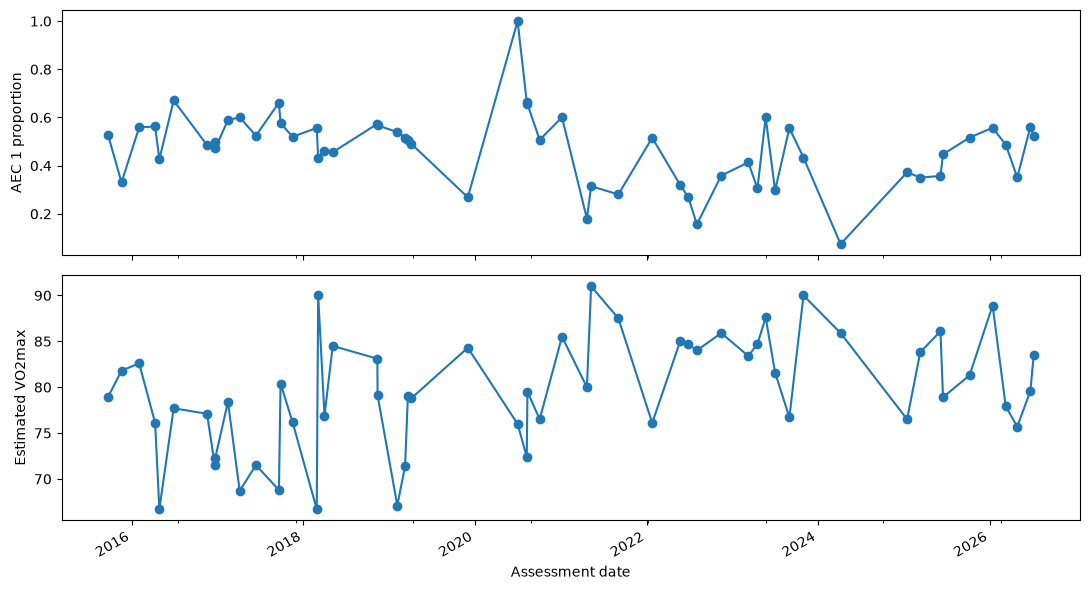

In [47]:
#Plot AEC 1 proportion and VO2max across assessment dates
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

historical_tests.plot(
    x="Date_of_test",
    y="aec1_share_28d",
    ax=axes[0],
    marker="o",
    legend=False
)

axes[0].set_ylabel("AEC 1 proportion")

historical_tests.plot(
    x="Date_of_test",
    y="VO2max",
    ax=axes[1],
    marker="o",
    legend=False
)

axes[1].set_ylabel("Estimated VO2max")
axes[1].set_xlabel("Assessment date")

plt.tight_layout()
plt.show()

In [50]:
#Create career progression variable
historical_tests["career_years"] = (
    historical_tests["Date_of_test"] -
    historical_tests["Date_of_test"].min()
).dt.days / 365.25

#Compare models with and without career progression
base_features = [
    "previous_VO2max",
    "days_between_tests",
    "aec1_share_28d"
]

data = historical_tests.dropna(
    subset=base_features + ["career_years", "VO2max"]
).copy()

for label, features in [
    ("Without career trend", base_features),
    ("With career trend", base_features + ["career_years"])
]:
    model = LinearRegression().fit(
        data[features], data["VO2max"]
    )

    aec_coefficient = model.coef_[
        features.index("aec1_share_28d")
    ]

    print(label, "AEC 1 coefficient:",
          round(aec_coefficient, 3))

Without career trend AEC 1 coefficient: -14.67
With career trend AEC 1 coefficient: -12.378


In [51]:
##Compare regression predictive accuracy with career progression included

data = data.sort_values("Date_of_test").copy()

baseline_features = [
    "previous_VO2max",
    "days_between_tests",
    "career_years"
]

aec_features = baseline_features + ["aec1_share_28d"]

actual = []
baseline_predictions = []
aec_predictions = []

for i in range(20, len(data)):
    train = data.iloc[:i]
    test = data.iloc[[i]]

    baseline = LinearRegression().fit(
        train[baseline_features], train["VO2max"]
    )

    aec_model = LinearRegression().fit(
        train[aec_features], train["VO2max"]
    )

    actual.append(test["VO2max"].iloc[0])

    baseline_predictions.append(
        baseline.predict(test[baseline_features])[0]
    )

    aec_predictions.append(
        aec_model.predict(test[aec_features])[0]
    )

print("Baseline + career MAE:",
      round(mean_absolute_error(actual, baseline_predictions), 3))

print("Baseline + career + AEC 1 MAE:",
      round(mean_absolute_error(actual, aec_predictions), 3))

Baseline + career MAE: 4.614
Baseline + career + AEC 1 MAE: 4.541


In [52]:
##Integrating Performance

In [53]:
#Load all event sheets from the athlete's race-history workbook
race_sheets = pd.read_excel(
    r"Slam races.xlsx",
    sheet_name=None)

#Inspect sheet names and number of races
for name, df in race_sheets.items():
    print(name, ":", len(df), "races")

200 Fr LC : 166 races
200 Fr SC : 68 races
200 IM LC : 187 races
200 IM SC : 64 races
100 Fr LC : 146 races
100 Fr SC : 42 races
Rounds Formula : 0 races


In [54]:
##Combine all races

#All race sheets, excluding formula sheet
race_history = pd.concat(
    [
        df.assign(
            Event=sheet.rsplit(" ", 1)[0],
            Course=sheet.rsplit(" ", 1)[1]
        )
        for sheet, df in race_sheets.items()
        if sheet != "Rounds Formula"
    ],
    ignore_index=True
)

print("Total races:", len(race_history))
print("\nColumns:")
print(race_history.columns.tolist())

print("\nFirst five races:")
display(race_history.head())

Total races: 673

Columns:
['Time', 'WA Pts', 'Round', 'Date', 'Meet', 'Venue', 'Club Swam Under', 'Level', 'Event', 'Course']

First five races:


,Time,WA Pts,Round,Date,Meet,Venue,Club Swam Under,Level,Event,Course
0,00:01:47.830000,846,Heat,2026-07-24,Commonweatlh Games 2026,Glasgow,NaN,1,200 Fr,LC
1,00:01:47.710000,849,Final,2026-06-27,SS National Open Championships,Edinburgh,UniOfStirl,1,200 Fr,LC
2,00:01:50.210000,792,Heat,2026-06-27,SS National Open Championships,Edinburgh,UniOfStirl,1,200 Fr,LC
3,00:01:45.440000,905,Final,2026-04-19,Aquatics GB Swimming Championships 2026,London,UniOfStirl,1,200 Fr,LC
4,00:01:47.260000,859,Heat,2026-04-19,Aquatics GB Swimming Championships 2026,London,UniOfStirl,1,200 Fr,LC


In [57]:
##Clean dates, convert race time to seconds

#Ensure dates are stored as datetime
race_history["Date"] = pd.to_datetime(
    race_history["Date"], errors="coerce"
)

#Convert mixed race-time formats into seconds
def convert_race_time(value):

    if pd.isna(value):
        return float("nan")

    # Times already stored as numeric seconds
    if isinstance(value, (int, float)):
        seconds = float(value)

    else:
        parts = str(value).strip().split(":")

        if len(parts) == 3:  # Hours:Minutes:Seconds
            seconds = (
                float(parts[0]) * 3600 +
                float(parts[1]) * 60 +
                float(parts[2])
            )

        elif len(parts) == 2:  # Minutes:Seconds
            seconds = float(parts[0]) * 60 + float(parts[1])

        else:
            seconds = float(parts[0])

    return seconds if seconds > 0 else float("nan")


race_history["RaceTime_s"] = (
    race_history["Time"].apply(convert_race_time)
)

print("Total races:", len(race_history))
print("Missing/invalid times:", race_history["RaceTime_s"].isna().sum())

display(
    race_history.groupby(["Event", "Course"])["RaceTime_s"]
    .agg(["count", "min", "max"])
    .round(2)
)

Total races: 673
Missing/invalid times: 0


count     min     max
Event  Course                       
100 Fr LC        146   47.87   72.33
       SC         42   46.09   67.96
200 Fr LC        166  104.26  159.71
       SC         68   99.83  184.64
200 IM LC        187  115.28  176.39
       SC         64  110.98  193.66

In [58]:
##Overlap with training history

#Identify period covered by completed swimming records
training_start = pd.to_datetime(planner_history["Date"]).min()
training_end = pd.to_datetime(planner_history["Date"]).max()

#Flag races with at least 28 days of potential training history
race_history["training_28d_available"] = (
    (race_history["Date"] >= training_start + pd.Timedelta(days=28)) &
    (race_history["Date"] <= training_end)
)

print("Training period:", training_start.date(), "to", training_end.date())

print("Total races:", len(race_history))
print("Races within eligible period:",
      race_history["training_28d_available"].sum())

display(
    race_history.groupby(["Event", "Course"])["training_28d_available"]
    .agg(["sum", "count"])
)

Training period: 2015-08-24 to 2026-08-16
Total races: 673
Races within eligible period: 403


sum  count
Event  Course            
100 Fr LC       86    146
       SC       18     42
200 Fr LC      106    166
       SC       42     68
200 IM LC      112    187
       SC       39     64

In [59]:
##Adding preceding training volume

#Prepare completed swimming history
training = planner_history.copy()

training["Date"] = pd.to_datetime(training["Date"])
training["Distance"] = pd.to_numeric(
    training["Distance"], errors="coerce"
).fillna(0)

#Keep races with potential 28-day training history
race_model = race_history[
    race_history["training_28d_available"]
].copy()

#Calculate completed swimming volume in the 28 days before each race
race_model["swim_28d_km"] = [
    training.loc[
        (training["Date"] >= race_date - pd.Timedelta(days=28)) &
        (training["Date"] < race_date),
        "Distance"
    ].sum()
    for race_date in race_model["Date"]
]

print("Race observations:", len(race_model))

display(
    race_model[
        ["Date", "Event", "Course", "RaceTime_s", "swim_28d_km"]
    ].head(10)
)

Race observations: 403


,Date,Event,Course,RaceTime_s,swim_28d_km
0,2026-07-24,200 Fr,LC,107.83,118.5
1,2026-06-27,200 Fr,LC,107.71,139.9
2,2026-06-27,200 Fr,LC,110.21,139.9
3,2026-04-19,200 Fr,LC,105.44,118.6
4,2026-04-19,200 Fr,LC,107.26,118.6
5,2026-02-20,200 Fr,LC,107.26,182.0
6,2026-02-20,200 Fr,LC,109.91,182.0
7,2025-05-26,200 Fr,LC,106.15,148.1
8,2025-05-26,200 Fr,LC,107.89,148.1
9,2025-05-21,200 Fr,LC,107.35,126.1


In [60]:
##Distribution of trianing volumes

#Summarise training volume by unique race date
race_days = (
    race_model.groupby("Date", as_index=False)
    .agg(
        n_races=("RaceTime_s", "size"),
        swim_28d_km=("swim_28d_km", "first")
    )
)

print("Unique race dates:", len(race_days))

print("\n28-day swimming volume summary:")
print(race_days["swim_28d_km"].describe().round(1))

print("\nLowest training volumes:")
display(
    race_days.nsmallest(10, "swim_28d_km")
)

Unique race dates: 207

28-day swimming volume summary:
count    207.0
mean     155.0
std       30.3
min       31.4
25%      136.0
50%      155.3
75%      178.5
max      219.8
Name: swim_28d_km, dtype: float64

Lowest training volumes:


,Date,n_races,swim_28d_km
118,2021-09-02,1,31.4
119,2021-09-03,2,37.4
120,2021-09-11,1,82.4
121,2021-09-12,2,88.4
185,2025-04-20,2,99.8
205,2026-08-15,2,101.5
184,2025-04-18,2,102.8
206,2026-08-16,1,103.5
0,2015-09-26,1,104.4
103,2020-11-21,1,107.9


In [61]:
##Historical performance baseline (last race)

#Find the best performance on each race date, for each event/course
previous_races = (
    race_history
    .groupby(["Event", "Course", "Date"], as_index=False)["RaceTime_s"]
    .min()
    .rename(columns={"RaceTime_s": "day_best_s"})
    .sort_values(["Event", "Course", "Date"])
)

#Get the best time from the previous race date
previous_races["previous_race_time_s"] = (
    previous_races
    .groupby(["Event", "Course"])["day_best_s"]
    .shift(1)
)

#Add the historical-performance baseline to our modelling dataset
race_model = race_model.drop(
    columns=["previous_race_time_s"], errors="ignore"
).merge(
    previous_races[
        ["Date", "Event", "Course", "previous_race_time_s"]
    ],
    on=["Date", "Event", "Course"],
    how="left",
    validate="many_to_one"
)

print("Total race observations:", len(race_model))
print("Races with previous performance:",
      race_model["previous_race_time_s"].notna().sum())

display(
    race_model[
        ["Date", "Event", "Course", "RaceTime_s",
         "previous_race_time_s", "swim_28d_km"]
    ].head(10)
)

Total race observations: 403
Races with previous performance: 403


,Date,Event,Course,RaceTime_s,previous_race_time_s,swim_28d_km
0,2026-07-24,200 Fr,LC,107.83,107.71,118.5
1,2026-06-27,200 Fr,LC,107.71,105.44,139.9
2,2026-06-27,200 Fr,LC,110.21,105.44,139.9
3,2026-04-19,200 Fr,LC,105.44,109.62,118.6
4,2026-04-19,200 Fr,LC,107.26,109.62,118.6
5,2026-02-20,200 Fr,LC,107.26,106.15,182.0
6,2026-02-20,200 Fr,LC,109.91,106.15,182.0
7,2025-05-26,200 Fr,LC,106.15,107.35,148.1
8,2025-05-26,200 Fr,LC,107.89,107.35,148.1
9,2025-05-21,200 Fr,LC,107.35,105.08,126.1


In [63]:
##Evaluate performance only prediction
##How accurately does previous performance predict the next race

#Calculate prediction error using the previous race performance
race_model["baseline_abs_error"] = (
    race_model["RaceTime_s"] -
    race_model["previous_race_time_s"]
).abs()

#Overall baseline accuracy
print(
    "Overall baseline MAE:",
    round(race_model["baseline_abs_error"].mean(), 3),
    "seconds"
)

#Baseline accuracy by event and course
baseline_summary = (
    race_model.groupby(["Event", "Course"])
    .agg(
        n_races=("RaceTime_s", "size"),
        baseline_MAE=("baseline_abs_error", "mean")
    )
    .round(3)
)

display(baseline_summary)

Overall baseline MAE: 1.922 seconds


n_races  baseline_MAE
Event  Course                       
100 Fr LC           86         0.852
       SC           18         0.531
200 Fr LC          106         1.926
       SC           42         1.801
200 IM LC          112         2.844
       SC           39         2.391

In [64]:
# Count race observations by round
print("Race rounds:")
print(
    race_model["Round"]
    .fillna("Unknown")
    .value_counts()
)

Race rounds:
Round
Final         192
Heat          178
Semi-Final     18
Semi-final      7
Relay           5
B-final         1
B-Final         1
Unknown         1
Name: count, dtype: int64


In [65]:
##Identify competitions with multiple swims (same event)

#Standardise round names
race_model["Round_clean"] = (
    race_model["Round"]
    .astype("string")
    .str.strip()
    .str.lower()
)

#Exclude relays
individual_races = race_model[
    race_model["Round_clean"].ne("relay").fillna(True)
].copy()

#Include year so recurring competitions aren't grouped together
individual_races["Meet_year"] = individual_races["Date"].dt.year

#Summarise races within each competition/event
competition_check = (
    individual_races
    .groupby(["Meet_year", "Meet", "Event", "Course"], as_index=False)
    .agg(
        n_races=("RaceTime_s", "size"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        best_time_s=("RaceTime_s", "min")
    )
)

competition_check["meet_days"] = (
    competition_check["last_date"] -
    competition_check["first_date"]
).dt.days + 1

print("Individual races:", len(individual_races))
print("Competition-event observations:", len(competition_check))
print("Groups with multiple races:",
      (competition_check["n_races"] > 1).sum())

print("\nLongest competition spans:")
display(
    competition_check.nlargest(10, "meet_days")
)

Individual races: 398
Competition-event observations: 190
Groups with multiple races: 172

Longest competition spans:


,Meet_year,Meet,Event,Course,n_races,first_date,last_date,best_time_s,meet_days
89,2020,2020 ISL Series,200 Fr,SC,5,2020-10-19,2020-11-22,100.25,35
90,2020,2020 ISL Series,200 IM,SC,5,2020-10-18,2020-11-21,111.66,35
68,2019,2019 ISL Series,200 IM,SC,2,2019-11-24,2019-12-21,111.85,28
88,2020,2020 ISL Series,100 Fr,SC,3,2020-10-19,2020-11-10,46.66,23
98,2021,2021 ISL Series,200 Fr,SC,4,2021-09-03,2021-09-24,101.72,22
99,2021,2021 ISL Series,200 IM,SC,4,2021-09-02,2021-09-23,112.63,22
97,2021,2021 ISL Series,100 Fr,SC,2,2021-09-03,2021-09-12,46.53,10
23,2016,Olympic Games 2016,100 Fr,LC,3,2016-08-09,2016-08-10,48.01,2
40,2017,Japan Open 2017,100 Fr,LC,2,2017-05-20,2017-05-21,48.86,2
42,2017,LEN European SC Swimming Championships 2017,100 Fr,SC,3,2017-12-16,2017-12-17,46.64,2


In [66]:
##Filter to finals only

#Keep finals from the full historical race dataset
historical_finals = race_history[
    race_history["Round"].astype("string").str.strip().str.lower() == "final"
].copy()

#Keep training-linked finals
performance_finals = race_model[
    race_model["Round"].astype("string").str.strip().str.lower() == "final"
].copy()

print("Historical finals:", len(historical_finals))
print("Training-linked finals:", len(performance_finals))

#Check whether any event/course has multiple finals on the same date
print(
    "Duplicate final dates:",
    historical_finals.duplicated(
        ["Date", "Event", "Course"]
    ).sum()
)

Historical finals: 273
Training-linked finals: 192
Duplicate final dates: 1
